# Training the spell network

This notebook is how the Larp Charm learns to recognise **spells**: gestures drawn in the air with the charm in your
hand (a circle, a zigzag, a flick, a heart). A small 1D CNN turns 1 to 6 seconds of accelerometer + gyro data into a
32-number **fingerprint**. The built-in spells are the nearest class prototype. Gestures you teach the charm later
are recognised from just 5 recordings, with no retraining.

It walks through every step, on the real recordings in [`dataset/`](../../../dataset):

1. **The data**: what the sensor sees, and what calibration says about its axes
2. **A baseline without machine learning** (DTW nearest neighbour), and where it fails
3. **Preprocessing and augmentation**
4. **The network**, and a training run with a learning curve
5. **5-fold cross-validation**: confusion matrix and the "no match" threshold
6. **Teach-your-own**: leave one gesture out, and three ways of recognising it
7. **The final model**: reproducing the shipped weights, folding batch norm for the charm, the fingerprint map

The same code lives in `spells_data.py`, `spells_model.py`, `dtw.py`, `evaluate.py` and `train.py`. `train.py`
writes the weights the charm (`firmware/LarpCharm/spells_model.h`) and the website (`spells-model.js`) run. The
whole story, with the on-device side, is in [docs/spells.md](../../../docs/spells.md).

| result (cross-validated, real recordings) | |
| --- | --- |
| built-in spells correct | 100%, none cast as another spell |
| "not a spell" rejected | 96.7% |
| a gesture taught from 5 recordings recognised | 91.9%, with 0.2% false matches |
| network on the charm (ESP32-S3) | 38,848 parameters, 69 ms |

In [1]:
%matplotlib inline
import numpy as np, pandas as pd, torch, torch.nn.functional as Fn
import matplotlib.pyplot as plt
from spells_data import load, stroke, active
from spells_model import BASE, T, Net, segment, to_input, augment, train, embed, prototypes
from dtw import dist, dtw_feat

DATA = '../../../dataset'
torch.set_num_threads(4)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 9})
COLS = ['#e4572e', '#29a35a', '#2e86de', '#f0a202', '#8e44ad', '#16a2b8']   # ax ay az gx gy gz
print('torch', torch.__version__, '| numpy', np.__version__)

torch 2.11.0 | numpy 2.5.3


## 1. The data

Recorded with the website's spells tab: hold your thumb on the charm's screen, hold still about half a second, draw
the gesture in the air, hold still, let go. The take goes to the website over Bluetooth. The charm's QMI8658 IMU is
sampled at exactly 100 Hz: accel in g (±8 g), gyro in °/s (±2048).

In [2]:
takes = load(DATA)
df = pd.DataFrame([{'label': t['label'], 'group': t['group'], 'seconds': t['n'] / t['hz']} for t in takes])
summary = df.groupby(['group', 'label'], sort=False).seconds.agg(takes='count', shortest='min', longest='max', total='sum').round(2)
print(f"{len(takes)} takes, {df.seconds.sum() / 60:.1f} minutes of motion, {sum(t['missed'] for t in takes)} samples missed")
summary

127 takes, 5.8 minutes of motion, 1 samples missed


takes  shortest  longest  total
group     label                                           
spell     circle              20      2.37     3.99  61.46
          zigzag              20      2.57     5.03  74.87
          flick               20      0.30     1.10   8.87
          heart               20      3.04     4.68  72.41
calibrate still                1     10.00    10.00  10.00
          screen-down          1      5.01     5.01   5.01
          top-down             1      5.00     5.00   5.00
          bottom-down          1      5.02     5.02   5.02
          left-down            1      5.01     5.01   5.01
          right-down           1      5.01     5.01   5.01
          turn-x               1      8.02     8.02   8.02
          turn-y               1      8.03     8.03   8.03
          turn-z               1      8.03     8.03   8.03
none      none                30      0.41     2.73  46.87
custom    anticlockcircle      8      2.57     3.58  25.51

### Calibration: which way the axes point

The charm lay still on each face, then was turned slowly about each axis. Gravity tells us the axes:

In [3]:
cal = {t['label']: t['x'] for t in takes if t['group'] == 'calibrate'}
rows = []
for pose in ['still', 'screen-down', 'top-down', 'bottom-down', 'left-down', 'right-down']:
    x = cal[pose]; a, g = x[:, :3].mean(0), x[:, 3:].mean(0)
    rows.append({'pose': pose, 'ax (g)': a[0], 'ay (g)': a[1], 'az (g)': a[2], '|a|': np.linalg.norm(a), 'gyro offset x (°/s)': g[0], 'y': g[1], 'z': g[2]})
pd.DataFrame(rows).set_index('pose').round(3)

,ax (g),ay (g),az (g),|a|,gyro offset x (°/s),y,z
pose,,,,,,,
still,0.157,0.137,-0.961,0.983,3.438,2.038,0.220
screen-down,0.044,0.033,1.031,1.032,1.590,2.795,0.191
top-down,-0.951,0.136,-0.036,0.961,4.211,2.349,0.239
bottom-down,1.014,0.184,-0.136,1.040,1.663,3.235,0.195
left-down,-0.063,1.033,-0.191,1.052,0.753,4.758,0.186
right-down,0.077,-0.926,-0.035,0.930,1.077,3.711,0.174


- **+X points to the top of the screen** (top edge down: −0.95 g; bottom edge down: +1.01 g)
- **+Y points to the right edge** (left edge down: +1.03 g; right edge down: −0.93 g)
- **+Z points into the screen**, away from you (screen up: −0.96 g; screen down: +1.03 g)

The accelerometer is within about 2%. The **gyro's resting offset is 1 to 5 °/s and changes from take to take**, so
every take is corrected using its own still first quarter second.

In [4]:
for axis, pose in zip('xyz', ['turn-x', 'turn-y', 'turn-z']):
    x = cal[pose]; ang = np.cumsum(x[:, 3:] - x[:25, 3:].mean(0), 0) / 100
    print(f'{pose}: angle swept about x, y, z = {np.round(ang.max(0) - ang.min(0)).astype(int)} degrees')

turn-x: angle swept about x, y, z = [ 22 193  30] degrees
turn-y: angle swept about x, y, z = [236  55  34] degrees
turn-z: angle swept about x, y, z = [ 21  13 219] degrees


(The turn instructions were "tip it forward" (mostly about Y), "turn it like a key" (about X) and "spin it flat"
(about Z); the labels describe the motion, not the axis.)

### What a take looks like

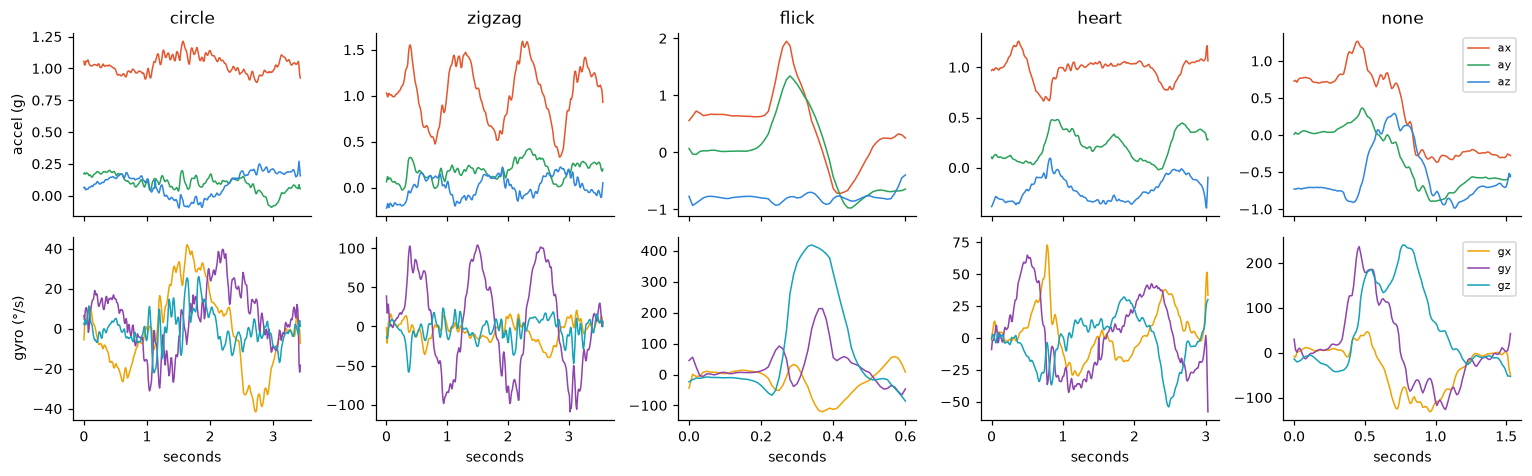

In [5]:
fig, axs = plt.subplots(2, 5, figsize=(14, 4.4), sharex='col')
for j, label in enumerate(['circle', 'zigzag', 'flick', 'heart', 'none']):
    x = [t for t in takes if t['label'] == label][2]['x']; tt = np.arange(len(x)) / 100
    for c in range(3):
        axs[0][j].plot(tt, x[:, c], color=COLS[c], lw=1, label='axayaz'[2 * c:2 * c + 2])
        axs[1][j].plot(tt, x[:, 3 + c], color=COLS[3 + c], lw=1, label='gxgygz'[2 * c:2 * c + 2])
    axs[0][j].set_title(label); axs[1][j].set_xlabel('seconds')
axs[0][0].set_ylabel('accel (g)'); axs[1][0].set_ylabel('gyro (°/s)')
axs[0][4].legend(fontsize=7, loc='upper right'); axs[1][4].legend(fontsize=7, loc='upper right')
plt.tight_layout()

### What the gyro alone sees

Integrating the gyro gives the direction the charm pointed while you drew it. The back of the charm swings left as it
turns about +X and up as it turns about +Y:

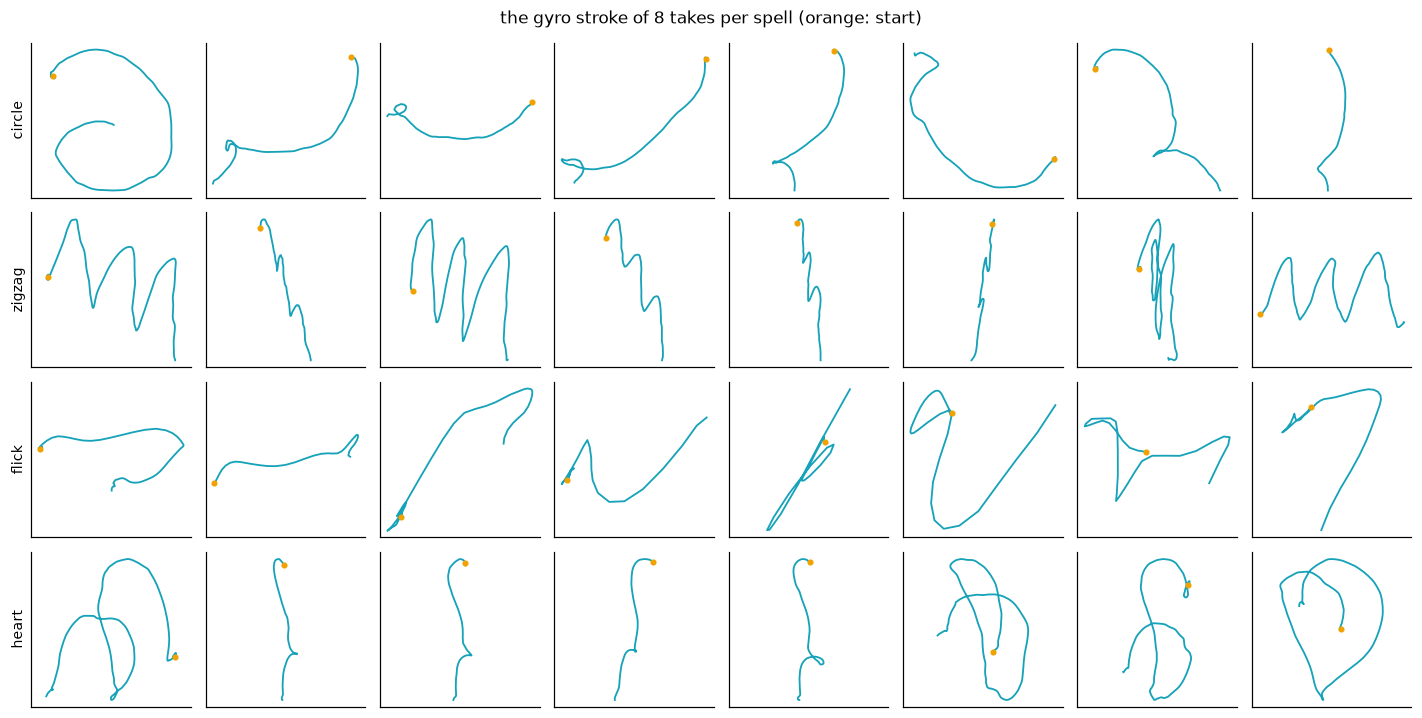

In [6]:
fig, axs = plt.subplots(4, 8, figsize=(13, 6.6))
for r, label in enumerate(['circle', 'zigzag', 'flick', 'heart']):
    for c, t in enumerate([t for t in takes if t['label'] == label][:8]):
        p = stroke(active(t['x'])); ax = axs[r][c]
        ax.plot(p[:, 0], p[:, 1], color='#16a2b8', lw=1.2); ax.plot(*p[0], 'o', color='#f0a202', ms=3)
        ax.invert_yaxis(); ax.set_aspect('equal', 'datalim'); ax.set_xticks([]); ax.set_yticks([])
        if c == 0: ax.set_ylabel(label)
plt.suptitle('the gyro stroke of 8 takes per spell (orange: start)'); plt.tight_layout()

The strokes are only **part** of each shape: circles come out as Js and Us, zigzags as tall squiggles. People draw
in the air mostly by **moving the arm** (only the accelerometer sees that) and partly by **turning the wrist**
(the gyro). So the network must use all six channels.

## 2. A baseline without machine learning

The classic approach: 1-nearest-neighbour with dynamic time warping (DTW) on all six channels, with 5 recorded
examples per class as templates. Every take is trimmed to its active part, gravity and the gyro offset are taken out,
and the gyro is scaled so 200 °/s counts like 1 g.

In [7]:
base = [t for t in takes if t['label'] in BASE]
S = [segment(t['x']) for t in base]
Y = np.array([BASE.index(t['label']) for t in base])
D = [dtw_feat(s) for s in S]
N = len(base)
M = np.zeros((N, N))
for i in range(N):
    for j in range(i + 1, N): M[i, j] = M[j, i] = dist(D[i], D[j])
rng = np.random.default_rng(0)
hits = np.zeros((5, 5))
for _ in range(200):
    tmpl = np.concatenate([rng.permutation(np.where(Y == c)[0])[:5] for c in range(5)])
    for i in set(range(N)) - set(tmpl): hits[Y[i], Y[tmpl[np.argmin(M[i, tmpl])]]] += 1
pd.DataFrame(hits / hits.sum(1, keepdims=True) * 100, index=BASE, columns=BASE).round(1).rename_axis('true \\ predicted')

,circle,zigzag,flick,heart,none
true \ predicted,,,,,
circle,99.7,0.1,0.0,0.2,0.0
zigzag,0.0,99.4,0.0,0.6,0.0
flick,13.2,0.0,77.1,9.4,0.3
heart,0.0,0.0,0.0,100.0,0.0
none,29.1,16.0,0.0,51.3,3.7


DTW tells the shapes apart almost perfectly, but it **cannot say "no match"**: "not a spell" has no consistent shape,
so a random fidget always lands nearest to *some* spell (only ~4% are recognised as "none"). The flick, a third of a
second long, is also weaker. Both are jobs for a learned model.

## 3. Preprocessing and augmentation

For the network every take becomes a fixed 7 × 128 input:

1. the gyro offset and the starting gravity are measured from the first 25 samples (the still start)
2. the take is trimmed to its **active part**: 20 samples before the gyro first passes 25 °/s, to 20 after it last does
3. channels: accel − gravity (g), and (gyro − offset) / 200
4. resampled to 128 steps; that throws away how long the gesture took, so a 7th channel gives it back as log(duration)

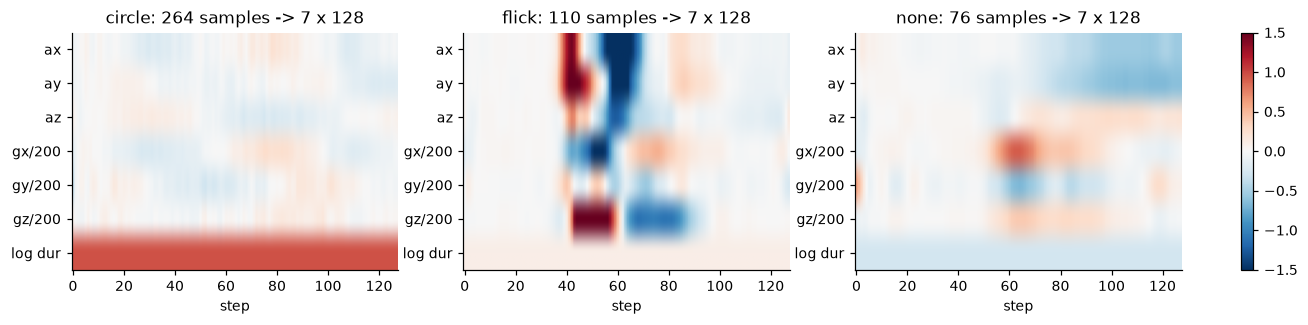

In [8]:
fig, axs = plt.subplots(1, 3, figsize=(14, 2.8))
for ax, label in zip(axs, ['circle', 'flick', 'none']):
    t = [t for t in base if t['label'] == label][0]
    x = to_input(segment(t['x']))
    im = ax.imshow(x, aspect='auto', cmap='RdBu_r', vmin=-1.5, vmax=1.5)
    ax.set_yticks(range(7), ['ax', 'ay', 'az', 'gx/200', 'gy/200', 'gz/200', 'log dur'])
    ax.set_title(f"{label}: {t['n']} samples -> 7 x {T}"); ax.set_xlabel('step')
plt.colorbar(im, ax=axs, fraction=0.02); plt.show()

**Augmentation.** 110 takes is very little, so every sample the network sees is a random variation of a real take:
a small 3D rotation (up to 15°, the same for accel and gyro, as if held at a slightly different angle), ±20% size,
a smooth time warp (drawn a little faster here, slower there), jittered trim points and sensor noise.

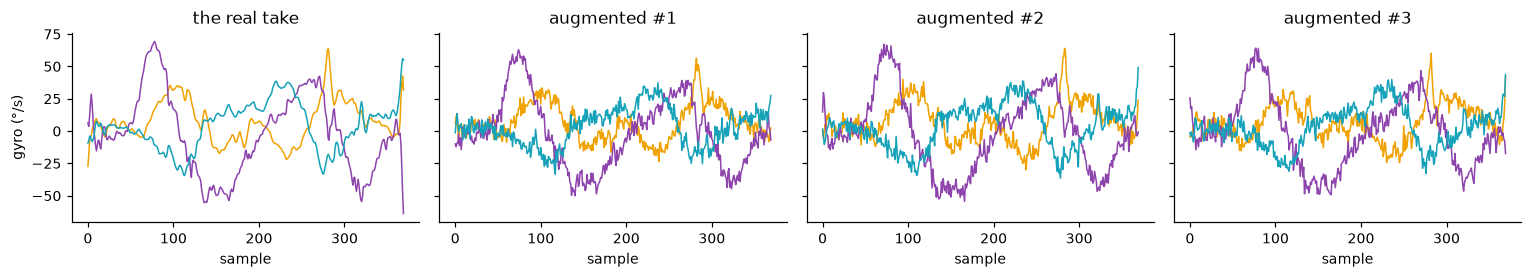

In [9]:
t = [t for t in base if t['label'] == 'heart'][0]; s = segment(t['x']); rng = np.random.default_rng(3)
fig, axs = plt.subplots(1, 4, figsize=(14, 2.6), sharey=True)
for k, ax in enumerate(axs):
    v = s if k == 0 else augment(s, rng)
    for c in range(3, 6): ax.plot(v[:, c] * 200, color=COLS[c], lw=1)
    ax.set_title('the real take' if k == 0 else f'augmented #{k}'); ax.set_xlabel('sample')
axs[0].set_ylabel('gyro (°/s)'); plt.tight_layout()

## 4. The network

Four 1D convolutions (batch norm + ReLU), the mean over time, a linear layer to 32 numbers, scaled to length 1:
the **fingerprint**. Training uses **cosine softmax**: the fingerprints are compared with normalised class weights
(scale 16), so they cluster by gesture on a sphere. That is what lets new gestures use them too.

In [10]:
net = Net()
print(net)
for name, p in net.named_parameters(): print(f'{name:12s} {tuple(p.shape)!s:16s} {p.numel():6,d}')
print(f'total {sum(p.numel() for p in net.parameters()):,} parameters ({sum(p.numel() for p in net.parameters()) * 4 / 1024:.0f} KB as float32)')

Net(
  (f): Sequential(
    (0): Sequential(
      (0): Conv1d(7, 32, kernel_size=(5,), stride=(1,), padding=(2,))
      (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
    )
    (1): Sequential(
      (0): Conv1d(32, 64, kernel_size=(5,), stride=(2,), padding=(2,))
      (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
    )
    (2): Sequential(
      (0): Conv1d(64, 64, kernel_size=(3,), stride=(2,), padding=(1,))
      (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
    )
    (3): Sequential(
      (0): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=(1,))
      (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
    )
  )
  (e): Linear(in_features=64, out_features=32, bias=True)
)
w            (5, 32)             160
f.0.0.weight (32, 7, 5)        1,120
f.0.0.bias 

### A training run, with a learning curve

The same recipe as `spells_model.train` (AdamW, one-cycle learning rate, label smoothing 0.05, 4 steps per epoch),
here on 80% of the takes, watching the held-out 20%:

held-out accuracy after 120 epochs: 95.5% on 22 takes


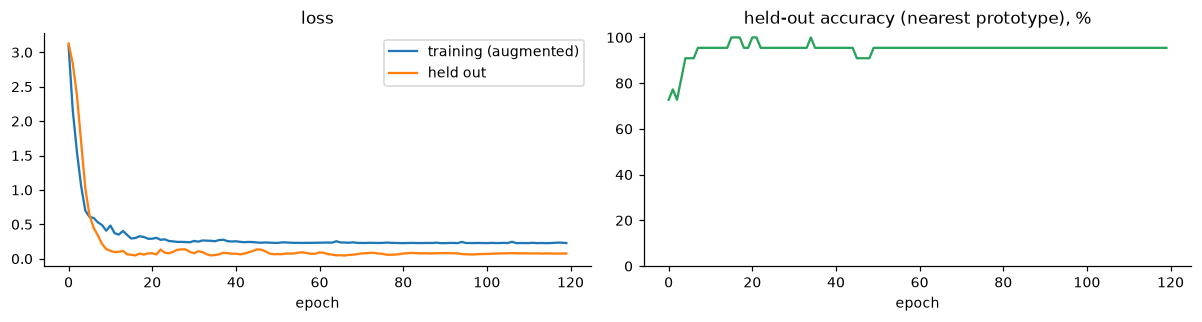

In [11]:
rng = np.random.default_rng(42)
val = np.concatenate([rng.permutation(np.where(Y == c)[0])[:max(2, int((Y == c).sum() * 0.2))] for c in range(5)])
tr = np.setdiff1d(np.arange(N), val)
torch.manual_seed(0); g = np.random.default_rng(0)
net = Net(); opt = torch.optim.AdamW(net.parameters(), 3e-3, weight_decay=1e-3)
EPOCHS = 120; sched = torch.optim.lr_scheduler.OneCycleLR(opt, 3e-3, total_steps=EPOCHS * 4)
yt = torch.tensor(Y); curve = []
Xval = torch.tensor(np.stack([to_input(S[i]) for i in val]))
for ep in range(EPOCHS):
    net.train(); tot = 0
    for chunk in np.array_split(g.permutation(tr), 4):
        loss = Fn.cross_entropy(net(torch.tensor(np.stack([to_input(S[i], g) for i in chunk]))), yt[chunk], label_smoothing=0.05)
        opt.zero_grad(); loss.backward(); opt.step(); sched.step(); tot += loss.item() / 4
    net.eval()
    with torch.no_grad():
        Etr = embed(net, [S[i] for i in tr]); P = prototypes(Etr, Y[tr], 5)
        vl = Fn.cross_entropy(net(Xval), yt[val]).item()
        acc = np.mean((embed(net, [S[i] for i in val]) @ P.T).argmax(1) == Y[val])
    curve.append((tot, vl, acc))
c = np.array(curve)
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
ax[0].plot(c[:, 0], label='training (augmented)'); ax[0].plot(c[:, 1], label='held out'); ax[0].set_title('loss'); ax[0].set_xlabel('epoch'); ax[0].legend()
ax[1].plot(c[:, 2] * 100, color='#29a35a'); ax[1].set_title('held-out accuracy (nearest prototype), %'); ax[1].set_xlabel('epoch'); ax[1].set_ylim(0, 102)
plt.tight_layout(); print(f'held-out accuracy after {EPOCHS} epochs: {c[-1, 2] * 100:.1f}% on {len(val)} takes')

## 5. 5-fold cross-validation

Every take is tested by a network that never saw it. A take is the class whose **prototype** (the mean fingerprint of
that class's training takes) is most similar. It is **"no match"** when that class is `none`, or when the similarity
is under a threshold.

In [12]:
rng = np.random.default_rng(1)
folds = np.zeros(N, int)
for c in range(5):
    idx = rng.permutation(np.where(Y == c)[0]); folds[idx] = np.arange(len(idx)) % 5
sim = np.zeros((N, 5))
for f in range(5):
    trn, te = folds != f, folds == f
    net = train([S[i] for i in np.where(trn)[0]], Y[trn], seed=f)
    P = prototypes(embed(net, [S[i] for i in np.where(trn)[0]]), Y[trn], 5)
    sim[te] = embed(net, [S[i] for i in np.where(te)[0]]) @ P.T
    print(f'fold {f + 1}/5 trained')
pred, best = sim.argmax(1), sim.max(1)
conf = pd.crosstab(pd.Series([BASE[i] for i in Y], name='true'), pd.Series([BASE[i] for i in pred], name='predicted')).reindex(index=BASE, columns=BASE, fill_value=0)
conf

fold 1/5 trained


fold 2/5 trained


fold 3/5 trained


fold 4/5 trained


fold 5/5 trained


predicted,circle,zigzag,flick,heart,none
true,,,,,
circle,20,0,0,0,0
zigzag,0,20,0,0,0
flick,0,0,20,0,0
heart,0,0,0,20,0
none,1,0,2,1,26


,spells right %,spells wrong %,"""not a spell"" rejected %"
threshold,,,
0.50,100.0,0.0,86.7
0.55,100.0,0.0,86.7
0.60,100.0,0.0,86.7
0.65,100.0,0.0,86.7
0.70,100.0,0.0,86.7
0.75,100.0,0.0,86.7
0.80,100.0,0.0,93.3
0.85,100.0,0.0,96.7
0.90,97.5,0.0,100.0


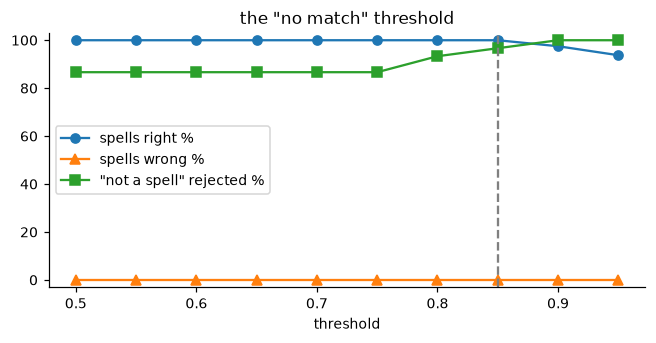

In [13]:
spell = Y != 4; rows = []
for thr in np.arange(0.5, 0.96, 0.05):
    cast = (pred != 4) & (best >= thr)
    rows.append({'threshold': round(thr, 2), 'spells right %': 100 * np.mean(cast[spell] & (pred[spell] == Y[spell])),
                 'spells wrong %': 100 * np.mean(cast[spell] & (pred[spell] != Y[spell])), '"not a spell" rejected %': 100 * np.mean(~cast[~spell])})
sweep = pd.DataFrame(rows).set_index('threshold')
sweep.plot(style=['o-', '^-', 's-'], figsize=(7, 3), ylim=(-3, 103), title='the "no match" threshold'); plt.axvline(0.85, ls='--', color='gray')
sweep.round(1)

The charm uses **0.85**: every spell still cast correctly, and 96.7% of "not a spell" rejected. That is exactly what
DTW could not do.

## 6. Teach-your-own

The real goal: any gesture, learnt from 5 recordings on the charm, without retraining. To test it honestly, **leave
one gesture out**: train the network without it, teach it from 5 random recordings, and test on the rest. Each spell
takes its turn, plus `anticlockcircle`, which no network ever trained on. Three ways to recognise the taught gesture:

- **cnn**: its prototype (the mean fingerprint of its 5 recordings) beats every built-in prototype
- **dtw**: the nearest stored recording (5 per built-in spell, plus its 5) is one of its own
- **hybrid** (what the charm runs): dtw, within 2× the spread of its 5 recordings, and the network doesn't veto
  (similarity to its prototype ≥ 0.3, and not more sure it is `none`)

In [14]:
cust = [t for t in takes if t['group'] == 'custom']
rows = []
for h in ['circle', 'zigzag', 'flick', 'heart', 'anticlockcircle']:
    hb = BASE.index(h) if h in BASE else -1
    keep = Y != hb; cls = [c for c in range(5) if c != hb]; remap = {c: i for i, c in enumerate(cls)}
    net = train([S[i] for i in np.where(keep)[0]], np.array([remap[c] for c in Y[keep]]), seed=7)
    P = prototypes(embed(net, [S[i] for i in np.where(keep)[0]]), np.array([remap[c] for c in Y[keep]]), len(cls)); ni = cls.index(4)
    hs = [segment(t['x']) for t in (cust if hb < 0 else base) if t['label'] == h]; He = embed(net, hs); Hd = [dtw_feat(s) for s in hs]
    others = np.where(keep)[0]; Oe = embed(net, [S[i] for i in others])
    res = {k: {'taught': [], 'spell': [], 'none': []} for k in ('cnn', 'dtw', 'hybrid')}
    for r in range(10):
        rg = np.random.default_rng(r); p = rg.permutation(len(hs)); en, ts = p[:5], p[5:]
        bt = [i for c in range(4) if c != hb for i in rg.permutation(np.where(Y == c)[0])[:5]]
        proto = He[en].mean(0); proto /= np.linalg.norm(proto)
        wmax = max(dist(Hd[a], Hd[b]) for a in en for b in en if a < b)
        def decide(e, d, skip=None):
            sb = e @ P.T; sc = e @ proto; dc = min(dist(d, Hd[k]) for k in en); db = min(dist(d, D[i]) for i in bt if i != skip)
            return {'cnn': sc > sb.max(), 'dtw': dc < db, 'hybrid': dc < db and dc <= 2 * wmax and sc >= 0.3 and not sb[ni] > sc}
        for i in ts:
            for k, v in decide(He[i], Hd[i]).items(): res[k]['taught'].append(v)
        for j, oi in enumerate(others[::2]):
            for k, v in decide(Oe[list(others).index(oi)], D[oi], skip=oi).items(): res[k]['none' if Y[oi] == 4 else 'spell'].append(v)
    for k in res: rows.append({'gesture': h, 'rule': k, 'recognised %': 100 * np.mean(res[k]['taught']),
                               'other spells taken for it %': 100 * np.mean(res[k]['spell']), '"not a spell" taken for it %': 100 * np.mean(res[k]['none'])})
    print(f'{h}: done')
teach = pd.DataFrame(rows)
teach.pivot_table(index='rule', values=['recognised %', 'other spells taken for it %', '"not a spell" taken for it %'], aggfunc='mean').round(1)

circle: done


zigzag: done


flick: done


heart: done


anticlockcircle: done


,"""not a spell"" taken for it %",other spells taken for it %,recognised %
rule,,,
cnn,7.1,0.0,87.5
dtw,19.7,1.5,92.8
hybrid,0.0,0.3,91.3


In [15]:
teach.pivot(index='gesture', columns='rule', values='recognised %').round(1)

rule,cnn,dtw,hybrid
gesture,,,
anticlockcircle,100.0,90.0,90.0
circle,74.7,100.0,94.7
flick,82.7,74.0,72.0
heart,90.7,100.0,100.0
zigzag,89.3,100.0,100.0


The **hybrid** keeps DTW's knack for new shapes and the network's knack for "no match": about 91% recognised, with
almost nothing else mistaken for it. (This notebook draws 10 random picks per gesture; `evaluate.py` draws 25, which
gives the 91.9% / 0.2% / 0% in the docs.) The flick is the hard case: a third of a second gives little to go on.

## 7. The final model

`train.py` trains on every take (seed 0, 160 epochs). Training is deterministic, so this reproduces the weights the
charm runs **exactly**:

In [16]:
final = train(S, Y, epochs=160, seed=0)
shipped = Net(); shipped.load_state_dict(torch.load('model/spells_cnn.pt')); shipped.eval()
diff = max((a - b).abs().max().item() for a, b in zip(final.state_dict().values(), shipped.state_dict().values()))
print(f'largest difference from the shipped weights (model/spells_cnn.pt): {diff:.1e}')

largest difference from the shipped weights (model/spells_cnn.pt): 0.0e+00


**Folding batch norm.** At inference a batch norm is just a per-channel scale and shift, so it folds into the
convolution before it: `w' = w * gamma / sqrt(var + eps)` and `b' = (b - mean) * gamma / sqrt(var + eps) + beta`. That leaves
four plain convolutions for the charm, written to `spells_model.h` as C arrays. A forward pass in numpy with the
folded weights, the same loop the charm's C and the website's JS run:

In [17]:
layers = []
for blk in shipped.f:
    conv, bn = blk[0], blk[1]; k = (bn.weight / torch.sqrt(bn.running_var + bn.eps)).detach()
    layers.append((conv.weight.detach().numpy() * k.numpy()[:, None, None], ((conv.bias.detach() - bn.running_mean) * k + bn.bias.detach()).numpy(), conv.stride[0], conv.padding[0]))
lw, lb = shipped.e.weight.detach().numpy(), shipped.e.bias.detach().numpy()
def fingerprint(x):
    for w, b, s, p in layers:
        n_out = (x.shape[1] + 2 * p - w.shape[2]) // s + 1; xp = np.pad(x, ((0, 0), (p, p)))
        x = np.maximum(sum(w[:, :, k] @ xp[:, k:k + s * (n_out - 1) + 1:s] for k in range(w.shape[2])) + b[:, None], 0)
    e = lw @ x.mean(1) + lb; return e / np.linalg.norm(e)
E = embed(shipped, S)
print(f'folded numpy vs PyTorch: largest difference {max(np.abs(fingerprint(to_input(S[i])) - E[i]).max() for i in range(N)):.1e}')

folded numpy vs PyTorch: largest difference 1.8e-07


On the charm the same network, in `spells_engine.h`, matches PyTorch to about 1.5 × 10⁻⁷ (`test_engine.cpp`) and runs
in **69 ms** on the ESP32-S3; the website's copy (`spells-net.js`) matches too (`test_net.js`).

### The fingerprint map

Every take's 32-number fingerprint, squashed to 2D with PCA (the charm's *map* view does exactly this, live, with
the same projection). `anticlockcircle` was never seen in training, yet it gets a place of its own:

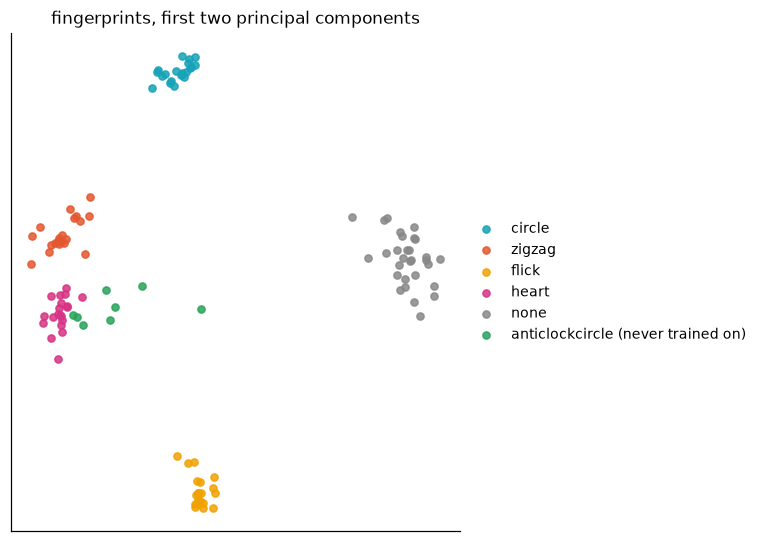

In [18]:
allt = [t for t in takes if t['group'] != 'calibrate']
Ea = embed(shipped, [segment(t['x']) for t in allt]); La = [t['label'] for t in allt]
mean = E.mean(0); _, _, Vt = np.linalg.svd(E - mean, full_matrices=False); Z = (Ea - mean) @ Vt[:2].T
fig, ax = plt.subplots(figsize=(7, 5))
for label, col in zip(['circle', 'zigzag', 'flick', 'heart', 'none', 'anticlockcircle'], ['#16a2b8', '#e4572e', '#f0a202', '#d63384', '#888888', '#29a35a']):
    m = np.array([l == label for l in La]); ax.scatter(Z[m, 0], Z[m, 1], s=22, color=col, label=label + (' (never trained on)' if label not in BASE else ''), alpha=.85)
ax.set_xticks([]); ax.set_yticks([]); ax.set_title('fingerprints, first two principal components'); ax.legend(loc='center left', bbox_to_anchor=(1, .5), frameon=False)
plt.tight_layout()

## Where to go from here

- **More sittings, more people.** Everything here is one person in one sitting, so cross-validation is optimistic.
  The real test is training on one sitting and testing on another, and on people the network has never seen.
- **A motion simulator** for arm-and-wrist drawing, to make hundreds of synthetic gesture classes, so the
  fingerprints generalise further and teach-your-own needs DTW less.
- **int8 weights** for the charm (about 40 KB instead of 155 KB, and faster).

To retrain and export after recording more: `python3 export_dataset.py <export>.json ../../../dataset`, then
`python3 evaluate.py ../../../dataset model/eval.json` and `python3 train.py ../../../dataset model/eval.json`.